# This is an outdated file. Refer to exploratory_data_analysis.ipynb for the newer file

# Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [59]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Load Data
Load data from pre-downloaded Oracle Elixer's Data from 2014 to 2025 to a local persistent database file for quick access on future sessions. This is for training and testing simple models.

*Uncomment the code below if you don't have a duckdb yet.*

In [2]:
# # Connect to persistent database file on disk
# con = duckdb.connect("lol_predictors.duckdb")

# oe_data_path = Path("./OE datasets")

# for dataset in oe_data_path.iterdir():
#     if dataset.is_file() and dataset.suffix == ".csv":
#         var_name = f"df_{dataset.name[:4]}" # e.g., df_2014
        
#         # Read CSV via pandas
#         df = pd.read_csv(dataset, low_memory=False)
        
#         # Save directly into a permanent DuckDB table in your file!
#         con.execute(f"CREATE OR REPLACE TABLE {var_name} AS SELECT * FROM df")
#         print(f"Saved {var_name} into DuckDB file.")

# con.close()

In [17]:
con = duckdb.connect("lol_predictors.duckdb")

# Data Overview

Select relevant data

In [18]:
def data_selection(df, included_cols):
    # Choose the dataset
    df = con.execute(f"""
    SELECT {", ".join(included_cols)}
    FROM {df}
    WHERE position = 'team';
    """).df()

    return df

In [32]:
cols_to_include = ['gameid', 'league', 'year', 'split', 'patch',
                   'teamname', 'gamelength', 'result', 'kills',
                   'deaths', 'assists', 'towers', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'goldspent'
                   ]

In [33]:
df_selected = "df_2014" # choose input next time, instead of a hardcoded df name
df = data_selection(df_selected, cols_to_include)

In [6]:
def data_profiling(df, df_selected=df_selected):
    """
    Present the profile of the dataframe, including
    description, number of missing values, number of unique values, and unique values of object series
    """
    # Display the data info
    print(f"{f" INFORMATION OF {df_selected} ":-^50}")
    df.info()
    print(f"Data Shape: {df.shape}")
    display(df.describe())
    
    with pd.option_context('display.max_seq_items', None): # list all columns of the df with no limits
        print(f"List of Columns: {df.columns}")
    
    with pd.option_context('display.max_rows', None): # list all rows of the df with no limits
        # State the number of missing items for each column
        print(f"\n{" COUNT OF MISSING VALUES ":-^50}") 
        display(df.isnull().sum())

        print(f"\n{" COUNT OF UNIQUE VALUES ":-^50}")
        display(df.nunique())

        print(f"\n{" UNIQUE VALUES OF OBJECT SERIES ":-^50}")
        for object_column in df.select_dtypes(include=['object']):
            if object_column == 'gameid': # skip gameid series
                continue
            print("\n",df[object_column].value_counts())


In [88]:
def detect_outliers(df, IQR_multiplier=1.5):
    """
    Utilizes box plots and IQR to detect outliers.
    """
    # Define numerical columns to visualize
    num_cols = df.select_dtypes(include=["number"]).columns.drop(['year', 'patch', 'result']).tolist()
    fig, axes = plt.subplots(3, 4, figsize=(16, 12)) # Adjust depending on the number of numerical columns
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(y=df[col], ax=axes[i])
        axes[i].set_title(col, fontsize=12, fontweight="bold")
        axes[i].set_ylabel("")

    # Hide unused subplots
    for j in range(len(num_cols), len(axes)):
        fig.delaxes(axes[j])

    print(f"{" BOXPLOTS OF NUMERICAL COLUMNS ":-^50}")
    plt.tight_layout()
    plt.show()



    print(f"\n{" COUNT OF OUTLIERS ":-^50}")
    for col in num_cols:
        # Setting the IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        # Standard 1.5 multiplier for outlier bounds
        lower_bound = Q1 - IQR_multiplier * IQR
        upper_bound = Q3 + IQR_multiplier * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(f"{f"{col}:":<25} {len(outliers):>5}")

--------- BOXPLOTS OF NUMERICAL COLUMNS ----------


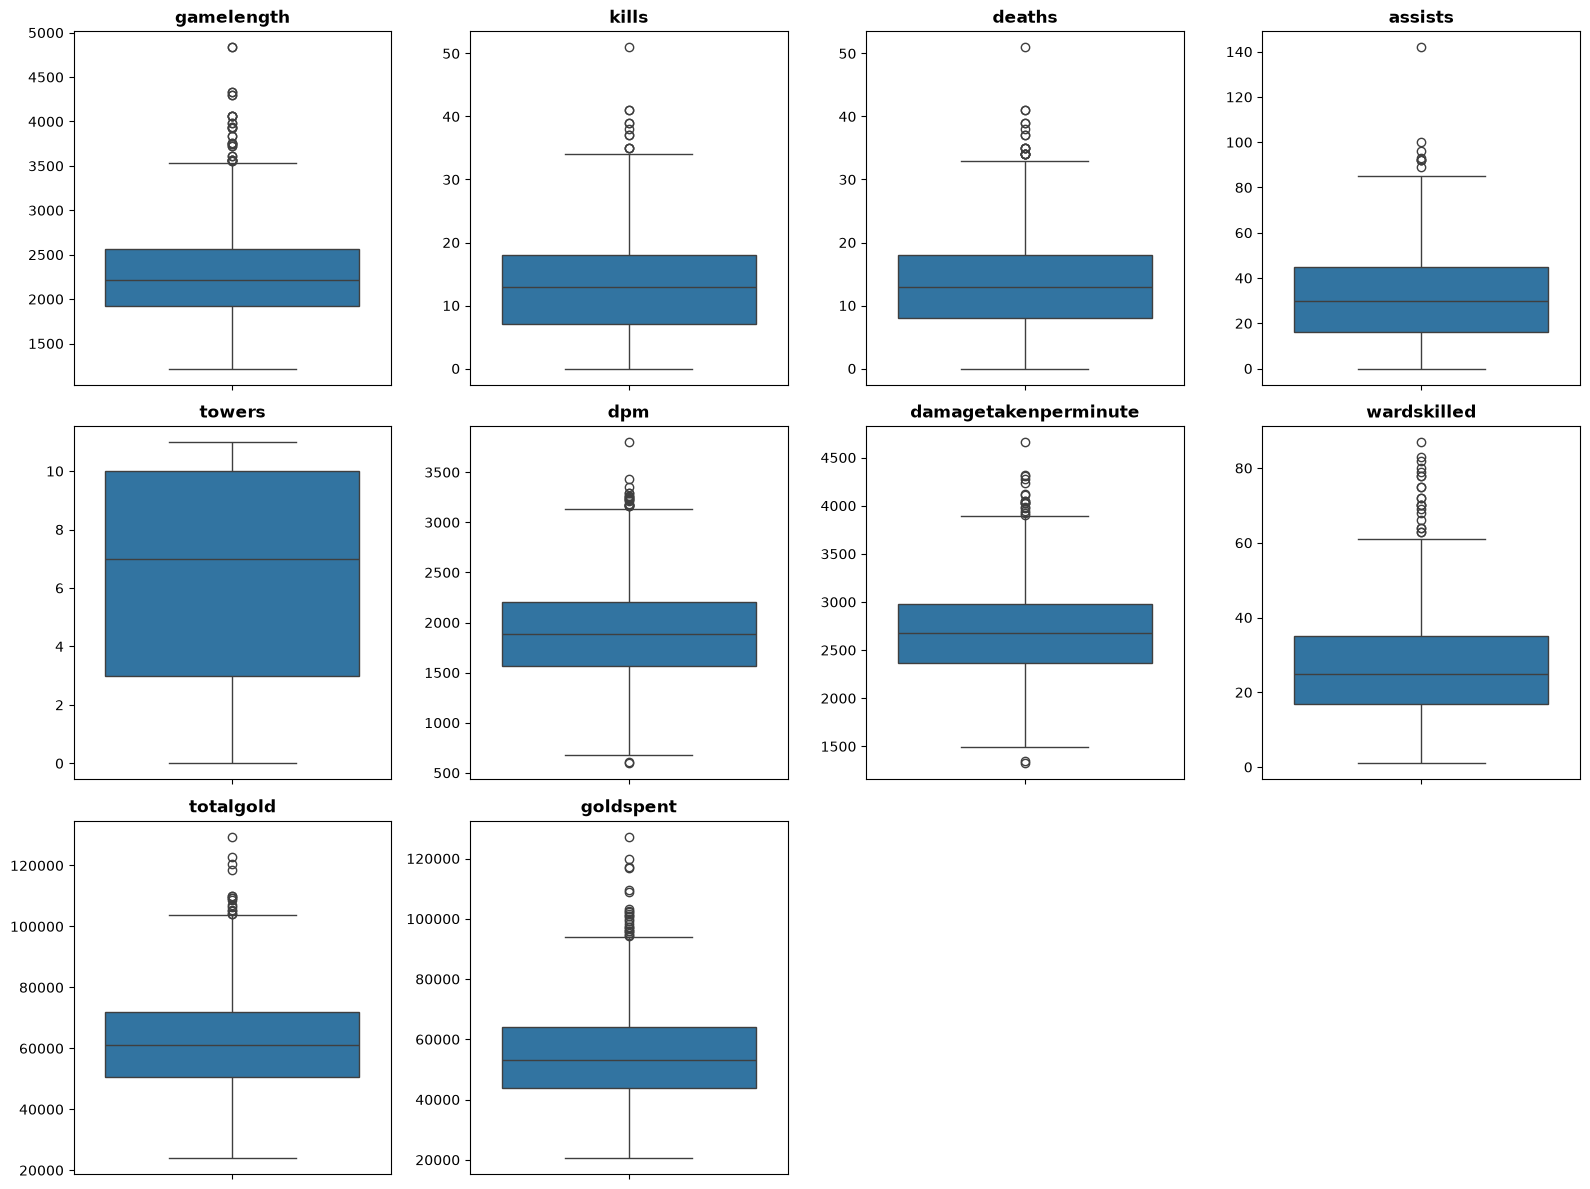


--------------- COUNT OF OUTLIERS ----------------
gamelength:                  32
kills:                       11
deaths:                      18
assists:                      8
towers:                       0
dpm:                         21
damagetakenperminute:        19
wardskilled:                 21
totalgold:                   15
goldspent:                   23


In [89]:
detect_outliers(df)

In [ ]:
def exploratory_data_analysis():
    pass

In [90]:
con.close()